<a href="https://colab.research.google.com/github/ranamammadlis/AGENT-BASED-EPIDEMIC-SIMULATION-GROUP-PROJECT/blob/main/Churn_Prediction_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [6]:
import pandas as pd

# reading the data
df = pd.read_csv('sample_data/Churn.csv')

# 1. take a look at the first 5 rows
print("--- First 5 rows ---")
display(df.head())

# 2. How many rows and columns
print("\n--- Data size---")
print(df.shape)

# 3. How much is churn
print("\n---target variable distribution---")
print(df['Churn'].value_counts())

--- First 5 rows ---


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



--- Data size---
(7043, 21)

---target variable distribution---
Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [7]:
# 1. analyzing the data types and lacking parts
print("--- data types of rows---")
df.info()

# 2. finding empty rows in TotalCharges row
empty_rows = df[df['TotalCharges'].str.strip() == '']
print(f"\n #nulls in TotalCharges: {len(empty_rows)}")

--- data types of rows---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling

In [8]:
import numpy as np

# 1. Turning empty rows into Nan values
df['TotalCharges'] = df['TotalCharges'].replace(' ', np.nan)

# 2. Filling up the Nans with '0' s
df['TotalCharges'] = df['TotalCharges'].fillna(0)

# 3. turning the text into float
df['TotalCharges'] = df['TotalCharges'].astype(float)

# control : all float?
print("--- New data types ---")
print(df[['TotalCharges']].dtypes)

--- New data types ---
TotalCharges    float64
dtype: object


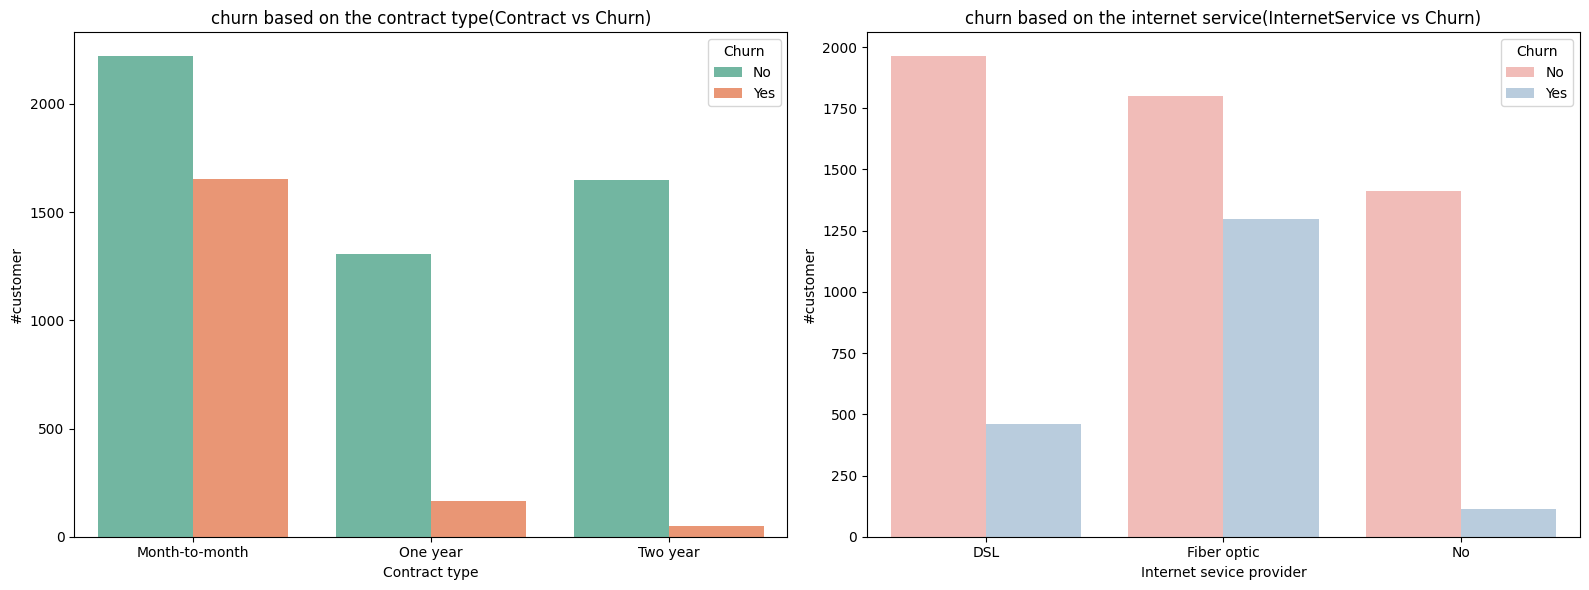

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# creating a place to make it look pretty
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. graf: churn ratios based on the contract type
sns.countplot(data=df, x='Contract', hue='Churn', palette='Set2', ax=axes[0])
axes[0].set_title('churn based on the contract type(Contract vs Churn)')
axes[0].set_xlabel('Contract type')
axes[0].set_ylabel('#customer')

# 2. Graf: churn ratio based on the internet service
sns.countplot(data=df, x='InternetService', hue='Churn', palette='Pastel1', ax=axes[1])
axes[1].set_title('churn based on the internet service(InternetService vs Churn)')
axes[1].set_xlabel('Internet sevice provider')
axes[1].set_ylabel('#customer')

plt.tight_layout()
plt.show()

In [10]:
# 3. proving the data in graphs

print("--- 1. churn based on the contract type(---")
contract_churn = df.groupby('Contract')['Churn'].value_counts(normalize=True).unstack() * 100
display(contract_churn.round(2))

print("\n--- 2. churn based on the internet service ---")
internet_churn = df.groupby('InternetService')['Churn'].value_counts(normalize=True).unstack() * 100
display(internet_churn.round(2))

--- 1. churn based on the contract type(---


Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83



--- 2. churn based on the internet service ---


Churn,No,Yes
InternetService,,
DSL,81.04,18.96
Fiber optic,58.11,41.89
No,92.60,7.40


In [11]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# 1. eliminating confusing rows like ids
ml_df = df.drop(columns=['customerID'])

# 2. turning text rows into 0 s or 1 s
le = LabelEncoder()
for col in ml_df.select_dtypes(include=['object']).columns:
    ml_df[col] = le.fit_transform(ml_df[col])

# 3. setting up the goals
X = ml_df.drop(columns=['Churn'])
y = ml_df['Churn']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("--- data preparation done---")
print(f"# customers in education set : {X_train.shape[0]}")
print(f"# customers in test set: {X_test.shape[0]}")

--- data preparation done---
# customers in education set : 5634
# customers in test set: 1409


In [12]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

model = RandomForestClassifier(n_estimators=100, random_state=42)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print("--- model test results ---")
print(f" Accuracy score of AI : %{accuracy * 100:.2f}")
print("\n--- detailed report  ---")
print(classification_report(y_test, y_pred))

--- model test results ---
 Accuracy score of AI : %79.49

--- detailed report  ---
              precision    recall  f1-score   support

           0       0.83      0.91      0.87      1036
           1       0.66      0.47      0.55       373

    accuracy                           0.79      1409
   macro avg       0.74      0.69      0.71      1409
weighted avg       0.78      0.79      0.78      1409



In [13]:
# SMOTE library
!pip install -U imbalanced-learn

import matplotlib.pyplot as plt
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

smote = SMOTE(random_state=42)
X_train_balanced, y_train_balanced = smote.fit_resample(X_train, y_train)

print("--- Data balanced ---")
print(f" Previous size : {X_train.shape[0]}")
print(f" New(edited)size : {X_train_balanced.shape[0]}\n")

model_balanced = RandomForestClassifier(n_estimators=100, random_state=42)
model_balanced.fit(X_train_balanced, y_train_balanced)

y_pred_balanced = model_balanced.predict(X_test)

print("--- New model test results(after SMOTE)---")
print(f"New Accuracy Score: %{accuracy_score(y_test, y_pred_balanced) * 100:.2f}")
print("\n--- New detailed report ---")
print(classification_report(y_test, y_pred_balanced))

--- Data balanced ---
 Previous size : 5634
 New(edited)size : 8276

--- New model test results(after SMOTE)---
New Accuracy Score: %77.86

--- New detailed report ---
              precision    recall  f1-score   support

           0       0.85      0.85      0.85      1036
           1       0.58      0.59      0.58       373

    accuracy                           0.78      1409
   macro avg       0.72      0.72      0.72      1409
weighted avg       0.78      0.78      0.78      1409



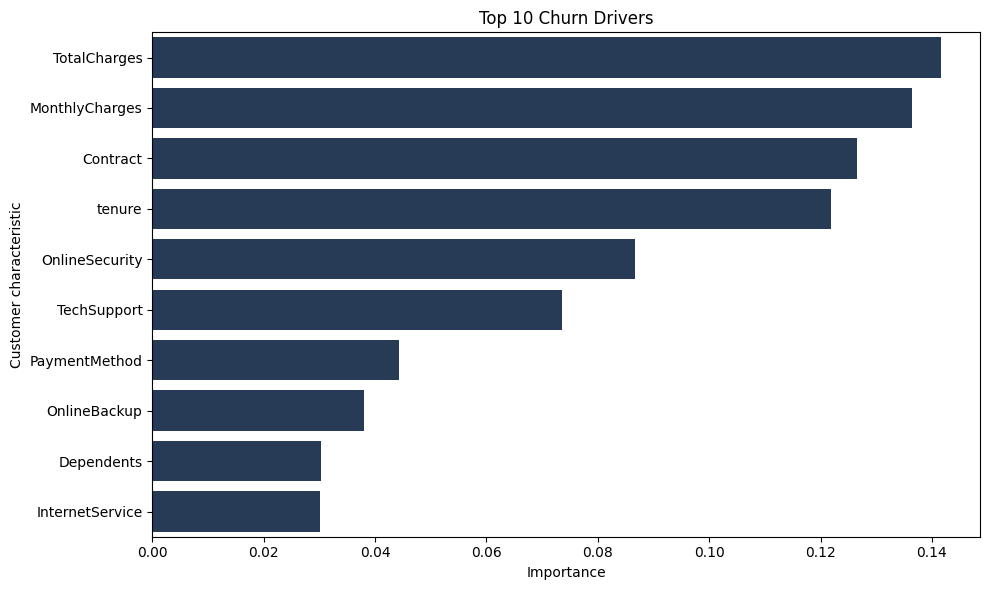

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

importances = model_balanced.feature_importances_
features = X.columns

feature_df = pd.DataFrame({'Feature': features, 'Importance': importances})
feature_df = feature_df.sort_values(by='Importance', ascending=False).head(10)

plt.figure(figsize=(10, 6))
sns.barplot(data=feature_df.head(10), x='Importance', y='Feature', color='#1f3a5f')
plt.title('Top 10 Churn Drivers')
plt.xlabel('Importance')
plt.ylabel('Customer characteristic')
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=200, bbox_inches='tight')
plt.show()